In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import sys
import os
import contractions
# General
import os
from pathlib import Path
#plotly stuff
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


In [2]:
# PATH PROJECT SETUP
PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)

Project path setup:
PROJECT_ROOT:   c:\Users\hanna\ADA\ada-2025-project-json-derulo
FIGURES_DIR:    c:\Users\hanna\ADA\ada-2025-project-json-derulo\figures

DATA_DIR:       c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest
JSON_DIR:       c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\contests.json
CSV_DIR:        c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data
CSV_CLEAN_DIR:  c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned
IMG_DIR:        c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\images


Loaded cleaned datasets – shape: (8863, 8)

Correlation with funny score:
# words: r = -0.046 (p = 0.000)
# characters: r = -0.056 (p = 0.000)


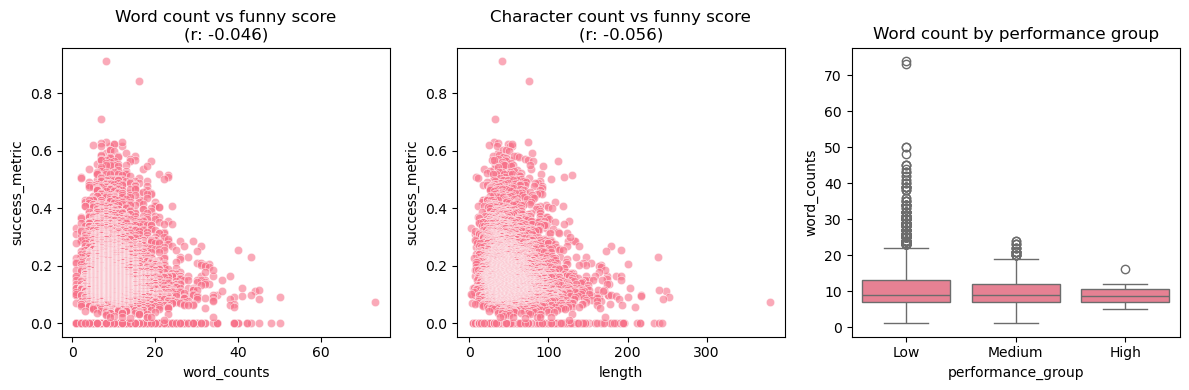

In [3]:


# ---- 1. Load cleaned CSVs ----
df = pd.concat([
    pd.read_csv(CSV_CLEAN_DIR / "510_cleaned.csv"),
    pd.read_csv(CSV_CLEAN_DIR / "895_cleaned.csv")
], ignore_index=True)

print("Loaded cleaned datasets – shape:", df.shape)

# ---- 2. Preprocessing ----
df["caption"] = df["caption"].fillna("")
df["caption"] = df["caption"].str.replace(r"[--]", " ", regex=True)
df["caption"] = df["caption"].str.replace(r"[.,?]", " ", regex=True)
df["caption"] = df["caption"].str.lower()
df["caption"] = df["caption"].apply(lambda x: contractions.fix(x))

# Metrics
df["word_counts"] = df["caption"].str.split().str.len()
df["length"] = df["caption"].str.len()

# ---- 3. Funny score metrics ----
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny']
df = df[df['total_votes'] > 0].copy()

df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny']) / df['total_votes']
df['success_metric'] = df['funny_score_weighted']

# ---- 4. Correlations ----
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\nCorrelation with funny score:")
print(f"# words: r = {corr_word_score:.3f} (p = {p_word:.3f})")
print(f"# characters: r = {corr_char_score:.3f} (p = {p_char:.3f})")

# ---- 5. Plot ----
plt.style.use('default')
sns.set_palette("husl")

df_filtered = df[(df['word_counts'] <= 100) & (df['length'] <= 400)]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df_filtered, x='word_counts', y='success_metric', alpha=0.6)
plt.title(f'Word count vs funny score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df_filtered, x='length', y='success_metric', alpha=0.6)
plt.title(f'Character count vs funny score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])
sns.boxplot(data=df, x='performance_group', y='word_counts')
plt.title('Word count by performance group')

plt.tight_layout()
plt.show()


In [4]:
# Make sure performance_group exists
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

# Initialize figure with 3 subplots
fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=[
        f'Word count vs funny score (r: {corr_word_score:.3f})',
        f'Length vs funny score (r: {corr_char_score:.3f})',
        'Word count by performance group'
    ]
)

# --- Subplot 1: Scatter (word count vs funny score) ---
fig.add_trace(
    go.Scatter(
        x=df_filtered['word_counts'],
        y=df_filtered['success_metric'],
        mode='markers',
        opacity=0.6,
        name="Word count scatter",
        marker=dict(color='blue'),
        hovertemplate='Word Count: %{x}<br>Funny Score: %{y:.3f}<extra></extra>'
    ),
    row=1, col=1
)

# --- Subplot 2: Scatter (length vs funny score) ---
fig.add_trace(
    go.Scatter(
        x=df_filtered['length'],
        y=df_filtered['success_metric'],
        mode='markers',
        opacity=0.6,
        name="Character count scatter",
        marker=dict(color='green'),
        hovertemplate='Length: %{x}<br>Funny Score: %{y:.3f}<extra></extra>'
    ),
    row=1, col=2
)

# --- Subplot 3: Boxplot (performance group) ---
for group, color in zip(['Low', 'Medium', 'High'], ['red', 'orange', 'purple']):
    fig.add_trace(
        go.Box(
            x=df[df['performance_group'] == group]['performance_group'],
            y=df[df['performance_group'] == group]['word_counts'],
            name=f'{group} group',
            marker_color=color,
            boxpoints='outliers',
            hovertemplate='Group: %{x}<br>Word Count: %{y}<extra></extra>'
        ),
        row=1, col=3
    )

# Layout adjustments
fig.update_layout(
    width=1200,
    height=500,
    title_text="Funny Score Analysis (Cleaned Data)",
    showlegend=False
)

fig.show()



In [9]:


# Create 1 row × 3 column subplot figure
fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=(
        f"Word count vs funny score<br>(r = {corr_word_score:.3f})",
        f"Character count vs funny score<br>(r = {corr_char_score:.3f})",
        "Word count by performance group"
    )
)

# --- Subplot 1: Scatter (word count vs funny score) ---
fig.add_trace(
    go.Scatter(
        x=df_filtered['word_counts'],
        y=df_filtered['success_metric'],
        mode='markers',
        opacity=0.6,
        name="Word count",
        hovertemplate='Word Count: %{x}<br>Funny Score: %{y:.3f}<extra></extra>'
    ),
    row=1, col=1
)

# --- Subplot 2: Scatter (length vs funny score) ---
fig.add_trace(
    go.Scatter(
        x=df_filtered['length'],
        y=df_filtered['success_metric'],
        mode='markers',
        opacity=0.6,
        name="Length",
        hovertemplate='Length: %{x}<br>Funny Score: %{y:.3f}<extra></extra>'
    ),
    row=1, col=2
)

# --- Subplot 3: Boxplot (performance group) ---
fig.add_trace(
    go.Box(
        x=df['performance_group'],
        y=df['word_counts'],
        name="Word count by group",
        boxpoints='outliers',
        hovertemplate='Group: %{x}<br>Word Count: %{y}<extra></extra>'
    ),
    row=1, col=3
)

# Final layout adjustments
fig.update_layout(
    width=1000,
    height=500,
    title_text="Funny Score Analysis (Cleaned Data)",
    showlegend=False
)

fig.show()


In [8]:
#for website
fig.write_html("structural_test.html", include_plotlyjs='cdn')  # 'cdn' loads Plotly JS from internet